# plutovizu — Écologie

API chaînable : chaque méthode retourne le graphique, on enchaîne les appels et on termine par `.show()`. Le thème **editorial** est appliqué dès l'import. Fiches détaillées (données attendues, paramètres) dans la [documentation](https://mr-kam.github.io/plutovizu/).

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from plutovizu import (Chart, get_fonts, list_themes, set_theme, texture_class,
                       theme_context)

## Écologie

Courbes de réponse des modèles, ordination des communautés et diversité (données **fictives**). Les calculs sont aussi dans `plutovizu.ecology`.

D² = 0.37 | coefficients : [ 2.645 -0.11 ]


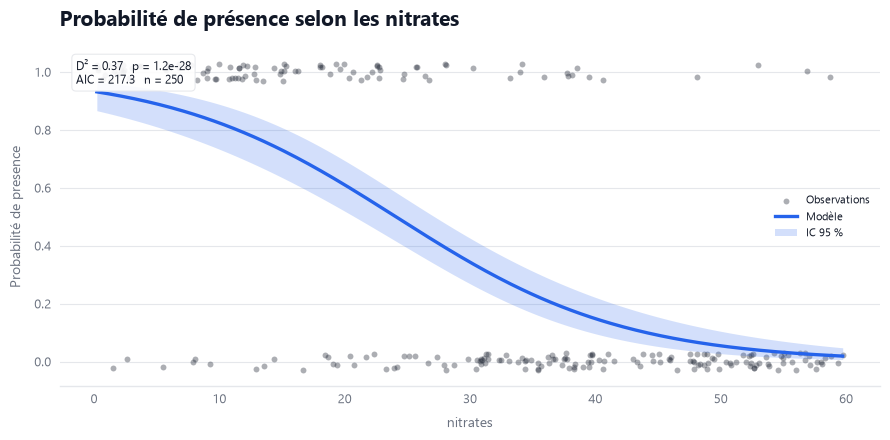

In [2]:
rng = np.random.default_rng(7)
nitrates = rng.uniform(0, 60, 250)
grenouille = pd.DataFrame({'nitrates': nitrates,
                           'presence': (rng.random(250) < 1 / (1 + np.exp(-(2.2 - 0.09 * nitrates)))).astype(int)})
chart = (Chart(grenouille, figsize=(9, 4.5))
    .glm_curve('nitrates', 'presence')
    .title('Probabilité de présence selon les nitrates')
    .tight_layout())
print('D² =', round(chart.glm['d2'], 2), '| coefficients :', chart.glm['coefs_original'].round(3))
chart.show()

{'moyenne': 2.5225, 'variance': 11.132324561403507, 'dispersion': 4.413210926225375, 'zeros_observes': 0.4525, 'zeros_poisson': 0.08025870895953036, 'zeros_binneg': 0.33381080109175854}


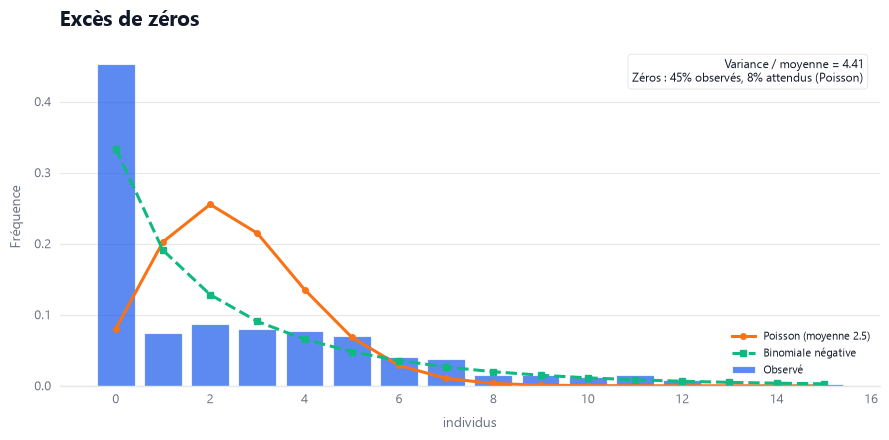

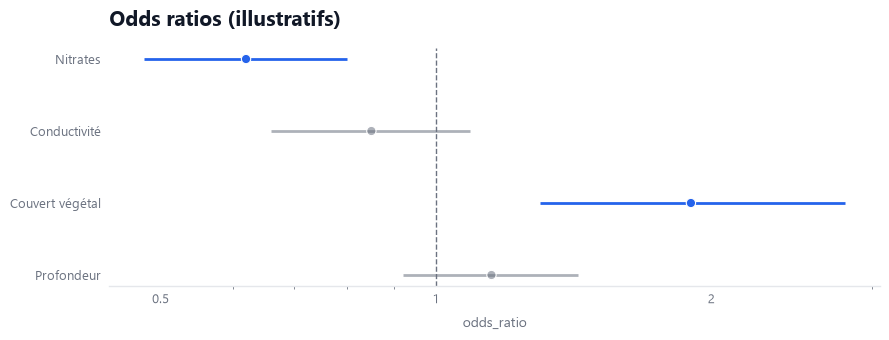

In [3]:
comptages = pd.DataFrame({'individus': np.where(rng.random(400) < .35, 0, rng.negative_binomial(3, .4, 400))})
chart = Chart(comptages, figsize=(9, 4.5)).count_distribution('individus').title('Excès de zéros').tight_layout()
print(chart.count_stats)
chart.show()

effets = pd.DataFrame({'variable': ['Nitrates', 'Conductivité', 'Couvert végétal', 'Profondeur'],
                       'odds_ratio': [0.62, 0.85, 1.9, 1.15], 'bas': [0.48, 0.66, 1.3, 0.92],
                       'haut': [0.80, 1.09, 2.8, 1.43]})
(Chart(effets, figsize=(9, 3.5))
    .forest_plot('variable', 'odds_ratio', 'bas', 'haut', ref=1, log=True)
    .title('Odds ratios (illustratifs)')
    .tight_layout()
    .show())

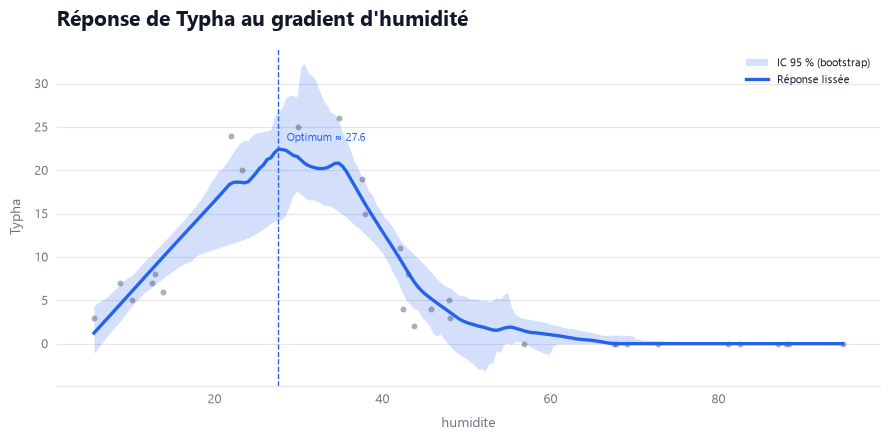

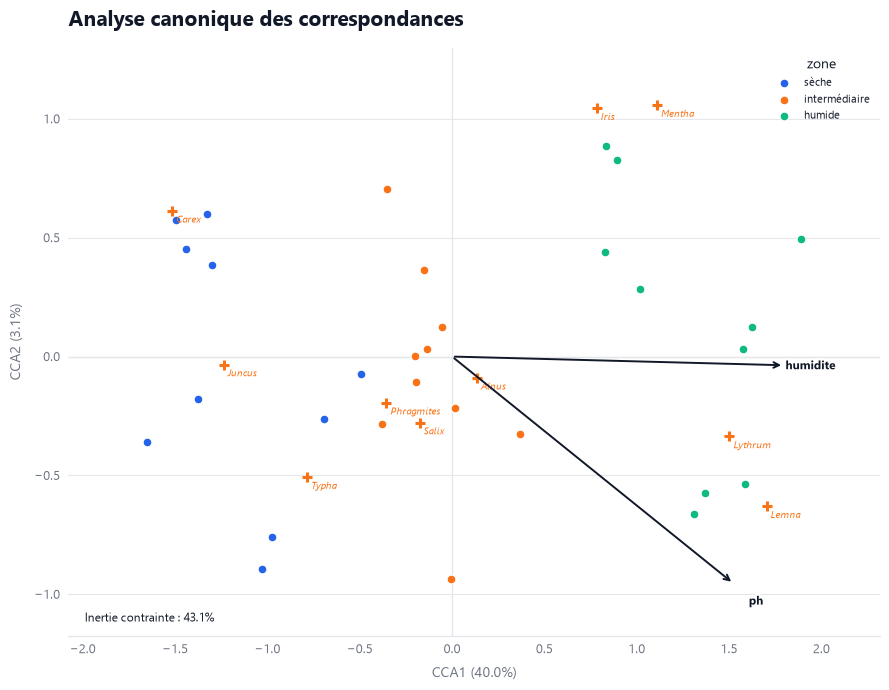

In [4]:
hum = np.sort(rng.uniform(5, 95, 30))
especes = ['Carex', 'Juncus', 'Typha', 'Phragmites', 'Salix', 'Alnus', 'Iris', 'Mentha', 'Lythrum', 'Lemna']
communaute = pd.DataFrame(rng.poisson(25 * np.exp(-((hum[:, None] - np.linspace(10, 90, 10)[None, :]) / 14) ** 2)),
                          columns=especes)
communaute['humidite'] = hum
communaute['ph'] = 6 + hum / 60 + rng.normal(0, .25, 30)
communaute['zone'] = pd.cut(hum, [0, 35, 65, 100], labels=['sèche', 'intermédiaire', 'humide']).astype(str)

(Chart(communaute, figsize=(9, 4.5))
    .response_curve('humidite', 'Typha', frac=0.4)
    .title('Réponse de Typha au gradient d\'humidité')
    .tight_layout()
    .show())

(Chart(communaute, figsize=(9, 7))
    .ordination(especes, env=['humidite', 'ph'], method='cca', group='zone')
    .title('Analyse canonique des correspondances')
    .tight_layout()
    .show())

{'s_obs': 10, 'chao2': 10.0, 'uniques': 0, 'duplicates': 0}


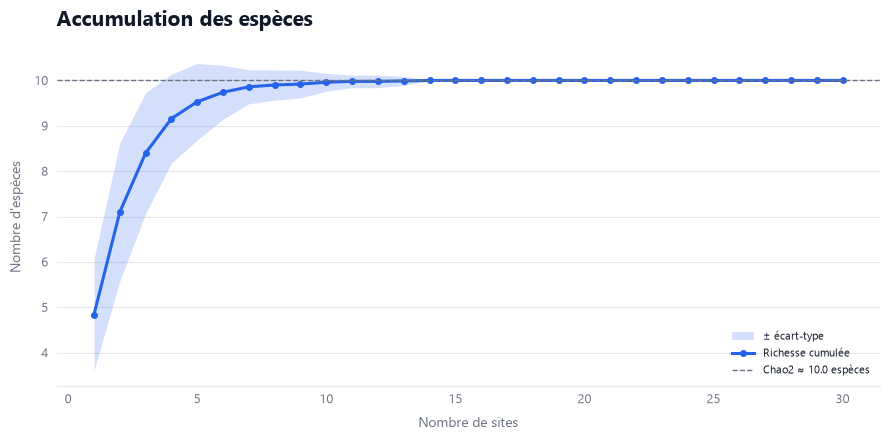

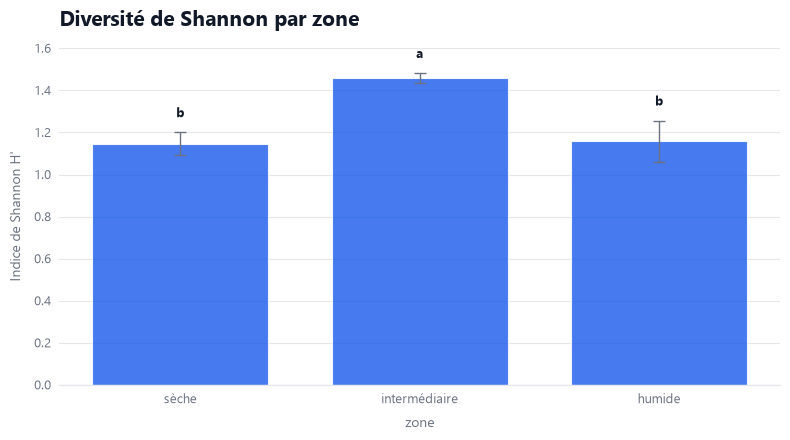

,richesse,shannon,simpson,inv_simpson,pielou,zone
0,3,0.894923,0.541016,2.178723,0.814594,sèche
1,3,1.007143,0.611531,2.574209,0.916741,sèche
2,3,0.954077,0.581612,2.390123,0.868438,sèche
3,4,1.090106,0.625185,2.667984,0.786345,sèche
4,4,1.094451,0.618213,2.619263,0.789480,sèche


In [5]:
chart = Chart(communaute, figsize=(9, 4.5)).accumulation(especes).title('Accumulation des espèces').tight_layout()
print(chart.accumulation_stats)
chart.show()

chart = (Chart(communaute, figsize=(8, 4.5))
    .diversity(especes, index='shannon', group='zone', letters=True)
    .title('Diversité de Shannon par zone')
    .tight_layout())
chart.show()
chart.diversity_table.head()